In [5]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

def strategy_test(start_date, end_date):
# Define parameters
  tickers = ['GC=F','USDCAD=X','JPY=X','SPY','BTC-USD']  # Forex pairs, Gold ETF, S&P 500 ETF


  risk_free_rate = 0.02  # Annual risk-free rate (2%)
  trading_days = 252  # Approximate trading days per year

  # Download historical close prices
  data = yf.download(tickers, start=start_date, end=end_date)['Close']
  data = data.dropna()  # Drop rows with missing data

  # Calculate daily returns
  daily_returns = data.pct_change().dropna()

  # Calculate portfolio returns
  portfolio_returns = (daily_returns * 1/len(tickers)).sum(axis=1)

  # Calculate cumulative returns
  cumulative_returns = (1 + portfolio_returns).cumprod()

  # Calculate annualized return
  total_return = cumulative_returns[-1] - 1
  days = (data.index[-1] - data.index[0]).days
  years = days / 365.25
  annualized_return = (1 + total_return) ** (1 / years) - 1

  # Calculate annualized volatility
  portfolio_volatility = portfolio_returns.std() * np.sqrt(trading_days)

  # Calculate Sharpe ratio (annualized)
  mean_daily_return = portfolio_returns.mean()
  std_daily_return = portfolio_returns.std()
  sharpe_ratio = (mean_daily_return * trading_days - risk_free_rate) / (std_daily_return * np.sqrt(trading_days))

  # Calculate maximum drawdown
  rolling_max = cumulative_returns.cummax()
  drawdowns = (cumulative_returns - rolling_max) / rolling_max
  max_drawdown = drawdowns.min()

  # Print results
  print(f"Portfolio Annualized Return: {annualized_return:.2%}")
  print(f"Portfolio Annualized Volatility: {portfolio_volatility:.2%}")
  print(f"Portfolio Sharpe Ratio (annualized): {sharpe_ratio:.2f}")
  print(f"Portfolio Maximum Drawdown: {max_drawdown:.2%}")
  print(f"Portfolio Cumulative Return: {(cumulative_returns[-1] - 1):.2%}")

  # Plot cumulative returns
  plt.figure(figsize=(10, 6))
  plt.plot(cumulative_returns.index, cumulative_returns, label='Portfolio Cumulative Return')
  plt.title('Equal-Weight Portfolio Cumulative Returns')
  plt.xlabel('Date')
  plt.ylabel('Cumulative Return')
  plt.grid(True)
  plt.legend()
  plt.show()

  # Plot drawdowns
  plt.figure(figsize=(10, 6))
  plt.plot(drawdowns.index, drawdowns, label='Portfolio Drawdown', color='red')
  plt.title('Portfolio Drawdown')
  plt.xlabel('Date')
  plt.ylabel('Drawdown')
  plt.grid(True)
  plt.legend()
  plt.show()

/tmp/ipython-input-2380397149.py:15: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(tickers, start=start_date, end=end_date)['Close']
[*********************100%***********************]  5 of 5 completed
/tmp/ipython-input-2380397149.py:28: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  total_return = cumulative_returns[-1] - 1
/tmp/ipython-input-2380397149.py:51: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  print(f"Portfolio Cumulative Return: {(cumulative_returns[-1] - 1):.2%}")


Portfolio Annualized Return: 26.10%
Portfolio Annualized Volatility: 16.35%
Portfolio Sharpe Ratio (annualized): 1.38
Portfolio Maximum Drawdown: -25.89%
Portfolio Cumulative Return: 406.37%


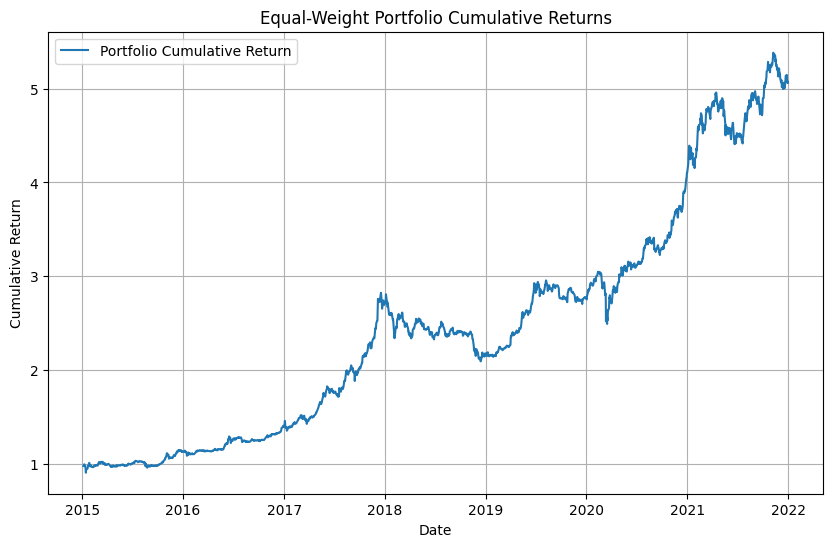

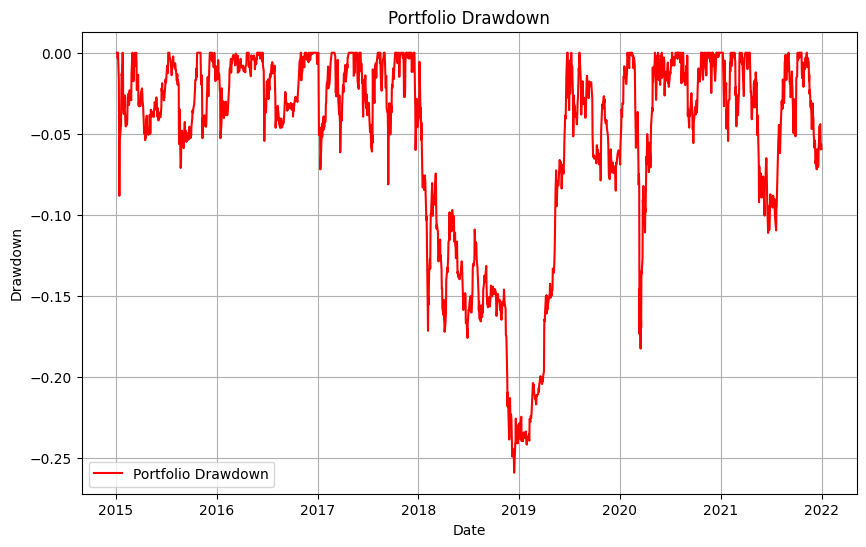

In [6]:
#insample
start_date = '2015-01-01'
end_date = '2022-01-01'
strategy_test(start_date, end_date)

/tmp/ipython-input-2380397149.py:15: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(tickers, start=start_date, end=end_date)['Close']
[*********************100%***********************]  5 of 5 completed
/tmp/ipython-input-2380397149.py:28: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  total_return = cumulative_returns[-1] - 1
/tmp/ipython-input-2380397149.py:51: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  print(f"Portfolio Cumulative Return: {(cumulative_returns[-1] - 1):.2%}")


Portfolio Annualized Return: 15.79%
Portfolio Annualized Volatility: 13.72%
Portfolio Sharpe Ratio (annualized): 1.00
Portfolio Maximum Drawdown: -18.87%
Portfolio Cumulative Return: 70.80%


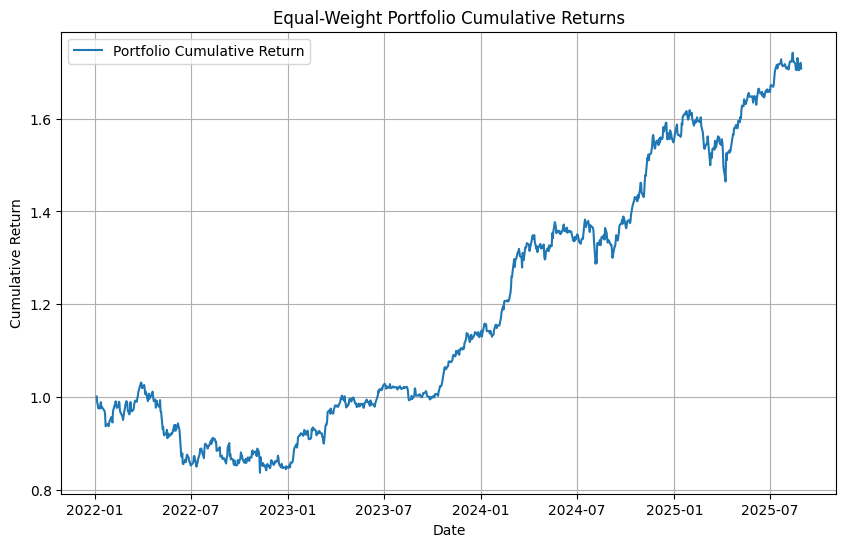

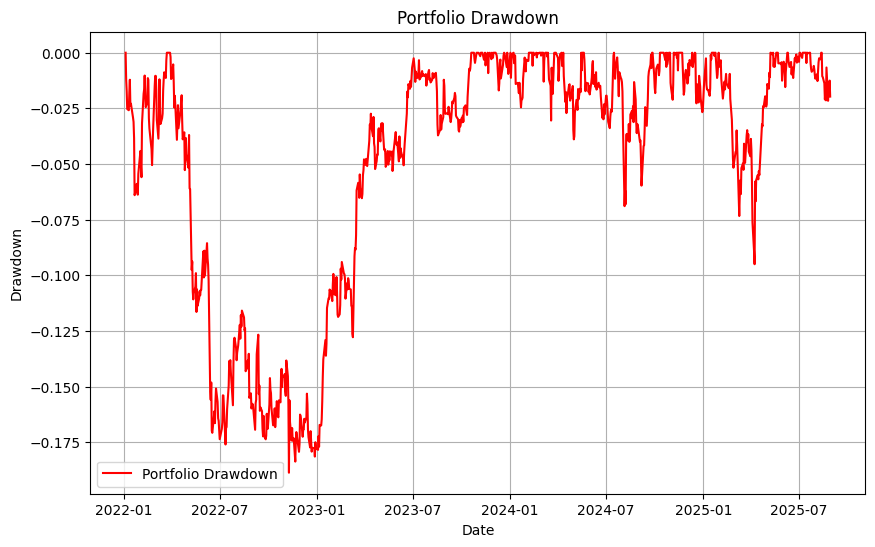

In [7]:
#outsample
start_date = '2022-01-01'
end_date = '2025-09-01'
strategy_test(start_date, end_date)